<a href="https://colab.research.google.com/github/Eduard1298/M-todos-de-aprendizaje-supervisado/blob/main/M%C3%A9todos_de_aprendizaje_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 TRANSPORTE TUNJA 

Total de viajes simulados: 350

Primeros 10 registros (paradas, distancia_km, hora_pico, lluvia, transbordo, tiempo_min):
[2, 1.05, 0, 0, 1, 19.8]
[2, 1.12, 0, 0, 1, 13.5]
[3, 1.95, 1, 1, 0, 36.0]
[2, 1.48, 0, 0, 1, 21.6]
[7, 4.42, 0, 0, 1, 36.4]
[3, 1.64, 0, 1, 1, 23.1]
[1, 0.5, 1, 0, 0, 11.4]
[3, 1.83, 1, 0, 0, 20.5]
[4, 2.55, 0, 1, 0, 28.9]
[1, 0.89, 0, 0, 0, 6.5]

Modelo de Regresión Lineal entrenado exitosamente.

Coeficientes (impacto de cada variable en el tiempo de viaje):
 - num_paradas: 5.66
 - distancia_km: -1.08
 - hora_pico: 7.92
 - lluvia: 4.59
 - transbordo: 7.17
Intercepto: 1.67

RMSE (error promedio): 3.82 minutos
R2 (ajuste del modelo): 0.892

Predicciones para nuevos viajes:
Viaje [4.  2.5 1.  0.  1. ] -> Tiempo estimado: 36.7 minutos
Viaje [2.  1.2 0.  1.  0. ] -> Tiempo estimado: 16.3 minutos


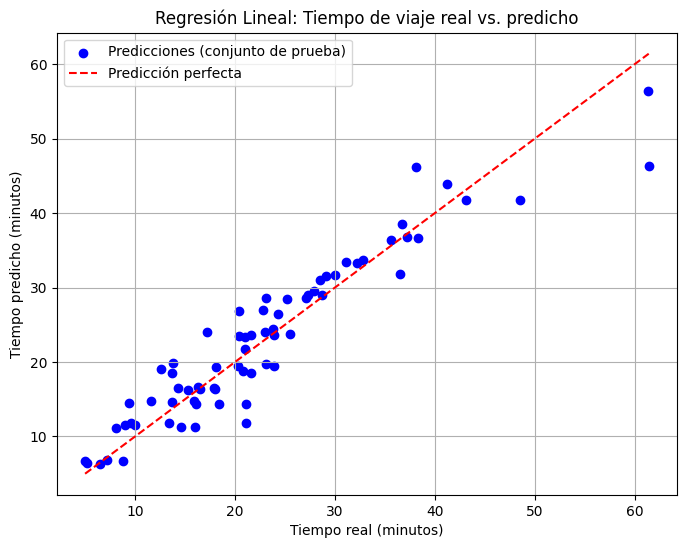

In [10]:
# ============================================================
# SISTEMA DE TRANSPORTE DE TUNJA
# Actividad 3 - Métodos de aprendizaje supervisado
# ============================================================
# Predicción del tiempo de viaje (minutos) a partir de las
# características del trayecto: número de paradas, distancia,
# hora pico, lluvia y si hubo transbordo.
# ============================================================

import random
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

print("==============================================")
print(" TRANSPORTE TUNJA ")
print("==============================================")


# ============================================================
# 1. BASE DE CONOCIMIENTO (lugares y rutas del sistema)
# ============================================================

LUGARES = [
    "Arboleda", "Avenida Norte", "Terminal", "Cooservicios",
    "La Fuente", "Plaza de Bolívar", "ESE Santiago de Tunja",
    "Muiscas", "Triunfo", "Runta", "Avenida Oriental", "Nieves",
    "Uniboyacá", "Pirgua", "Estadio", "Retén Sur", "Asís",
    "Avenida Universitaria", "C.C. Viva", "San Francisco", "Florida"
]

RUTAS = {
    "R1": ["Arboleda", "Avenida Norte", "Terminal"],
    "R8": ["Cooservicios", "La Fuente", "Plaza de Bolívar", "Terminal", "ESE Santiago de Tunja"],
    "R9": ["Arboleda", "Avenida Norte", "La Fuente", "Avenida Universitaria"],
    "R10": ["Muiscas", "Avenida Norte", "Triunfo"],
    "R12": ["Runta", "Avenida Oriental", "Nieves", "Avenida Norte", "Muiscas", "Uniboyacá", "Plaza de Bolívar"],
    "R15": ["Cooservicios", "Avenida Norte", "Muiscas"],
    "R20": ["Pirgua", "Terminal", "Avenida Norte", "Arboleda"],
    "R21": ["Pirgua", "Terminal", "Estadio", "Retén Sur"],
    "R22": ["Asís", "Muiscas", "Avenida Universitaria", "C.C. Viva", "Terminal", "La Fuente"],
    "R23": ["Arboleda", "Uniboyacá", "Florida", "San Francisco"]
}

TIEMPOS_RUTA = {
    "R1": 15, "R8": 20, "R9": 20, "R10": 15, "R12": 30,
    "R15": 20, "R20": 20, "R21": 20, "R22": 25, "R23": 25
}

TIEMPO_TRANSBORDO = 5


def buscar_ruta_directa(origen, destino):
    for nombre_ruta, lugares in RUTAS.items():
        for sentido in [lugares, list(reversed(lugares))]:
            if origen in sentido and destino in sentido:
                p_origen = sentido.index(origen)
                p_destino = sentido.index(destino)
                if p_origen < p_destino:
                    return nombre_ruta, sentido[p_origen:p_destino + 1]
    return None


def buscar_ruta_con_transbordo(origen, destino):
    for ruta_1, lugares_1_o in RUTAS.items():
        for lugares_1 in [lugares_1_o, list(reversed(lugares_1_o))]:
            if origen not in lugares_1:
                continue
            p_origen = lugares_1.index(origen)

            for ruta_2, lugares_2_o in RUTAS.items():
                if ruta_1 == ruta_2:
                    continue
                for lugares_2 in [lugares_2_o, list(reversed(lugares_2_o))]:
                    if destino not in lugares_2:
                        continue
                    p_destino = lugares_2.index(destino)

                    for lugar in lugares_1:
                        if lugar not in lugares_2:
                            continue
                        p_t1 = lugares_1.index(lugar)
                        p_t2 = lugares_2.index(lugar)
                        if p_origen < p_t1 and p_t2 <= p_destino:
                            tramo_1 = lugares_1[p_origen:p_t1 + 1]
                            tramo_2 = lugares_2[p_t2:p_destino + 1]
                            return ruta_1, ruta_2, tramo_1, tramo_2
    return None


def simular_viaje(origen, destino):
    resultado = buscar_ruta_directa(origen, destino)

    if resultado:
        ruta, recorrido = resultado
        num_paradas = len(recorrido) - 1
        transbordo = 0
        tiempo_base = TIEMPOS_RUTA[ruta] * (num_paradas / (len(RUTAS[ruta]) - 1))
    else:
        resultado = buscar_ruta_con_transbordo(origen, destino)
        if not resultado:
            return None

        ruta_1, ruta_2, tramo_1, tramo_2 = resultado
        num_paradas = (len(tramo_1) - 1) + (len(tramo_2) - 1)
        transbordo = 1

        t1 = TIEMPOS_RUTA[ruta_1] * ((len(tramo_1) - 1) / (len(RUTAS[ruta_1]) - 1))
        t2 = TIEMPOS_RUTA[ruta_2] * ((len(tramo_2) - 1) / (len(RUTAS[ruta_2]) - 1))
        tiempo_base = t1 + t2 + TIEMPO_TRANSBORDO

    hora_pico = random.choices([0, 1], weights=[0.55, 0.45])[0]
    lluvia = random.choices([0, 1], weights=[0.65, 0.35])[0]

    distancia_km = round(max(0.3, num_paradas * 0.6 + random.uniform(-0.2, 0.3)), 2)

    efecto_hora_pico = random.uniform(5, 10) if hora_pico else 0
    efecto_lluvia = random.uniform(3, 7) if lluvia else 0
    ruido = random.gauss(0, 2.5)

    tiempo_viaje = max(5.0, round(tiempo_base + efecto_hora_pico + efecto_lluvia + ruido, 1))

    return [num_paradas, distancia_km, hora_pico, lluvia, transbordo, tiempo_viaje]


# ============================================================
# 2. PREPARACIÓN DE LOS DATOS (Conjunto de entrenamiento)
# ============================================================
# Cada fila: [num_paradas, distancia_km, hora_pico, lluvia, transbordo, tiempo_viaje_min]

random.seed(42)

filas = []
intentos = 0
while len(filas) < 350 and intentos < 350 * 20:
    intentos += 1
    origen, destino = random.choice(LUGARES), random.choice(LUGARES)
    if origen == destino:
        continue
    fila = simular_viaje(origen, destino)
    if fila:
        filas.append(fila)

datos = np.array(filas)

# Variables de entrada (X) y variable a predecir (y)
X = datos[:, 0:5]          # num_paradas, distancia_km, hora_pico, lluvia, transbordo
y = datos[:, 5]            # tiempo_viaje_min

print(f"\nTotal de viajes simulados: {len(X)}")
print("\nPrimeros 10 registros (paradas, distancia_km, hora_pico, lluvia, transbordo, tiempo_min):")
for i in range(10):
    print(filas[i])


# ============================================================
# 3. CREACIÓN Y ENTRENAMIENTO DEL MODELO (Supervisado)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)

print("\nModelo de Regresión Lineal entrenado exitosamente.")
print("\nCoeficientes (impacto de cada variable en el tiempo de viaje):")
variables = ["num_paradas", "distancia_km", "hora_pico", "lluvia", "transbordo"]
for nombre, coef in zip(variables, modelo.coef_):
    print(f" - {nombre}: {coef:.2f}")
print(f"Intercepto: {modelo.intercept_:.2f}")


# ============================================================
# 4. EVALUACIÓN DEL MODELO
# ============================================================

predicciones = modelo.predict(X_test)

mse = mean_squared_error(y_test, predicciones)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predicciones)

print(f"\nRMSE (error promedio): {rmse:.2f} minutos")
print(f"R2 (ajuste del modelo): {r2:.3f}")


# ============================================================
# 5. PREDICCIÓN CON NUEVOS DATOS (Inferencia)
# ============================================================

nuevos_viajes = np.array([
    [4, 2.5, 1, 0, 1],
    [2, 1.2, 0, 1, 0]
])

predicciones_nuevas = modelo.predict(nuevos_viajes)

print("\nPredicciones para nuevos viajes:")
for i in range(len(nuevos_viajes)):
    print(f"Viaje {nuevos_viajes[i]} -> Tiempo estimado: {predicciones_nuevas[i]:.1f} minutos")


# ============================================================
# 6. VISUALIZACIÓN DE LOS RESULTADOS
# ============================================================

plt.figure(figsize=(8, 6))
plt.scatter(y_test, predicciones, color="blue", label="Predicciones (conjunto de prueba)")
lim_min, lim_max = min(y_test.min(), predicciones.min()), max(y_test.max(), predicciones.max())
plt.plot([lim_min, lim_max], [lim_min, lim_max], color="red", linestyle="--", label="Predicción perfecta")
plt.title("Regresión Lineal: Tiempo de viaje real vs. predicho")
plt.xlabel("Tiempo real (minutos)")
plt.ylabel("Tiempo predicho (minutos)")
plt.legend()
plt.grid(True)
plt.show()

